
### **INSTALL PACKAGES AND MOUNT DRIVE**

In [15]:
!pip install --upgrade qiskit qiskit-aer qiskit-ibm-provider
!pip install yfinance pandas numpy matplotlib scipy pylatexenc
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **IMPORTS**

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from IPython.display import display
from scipy.stats import zscore
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import Diagonal, QFT
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

# **LOAD CSV DATA & SOME INIT**

In [17]:
csv_path = "/content/drive/MyDrive/Winter 2025/CPS840/Research /tech_stock_data.csv"
stock_data = pd.read_csv(csv_path)

# For later graphing we want an array of stock names.
# we pad with a placeholder.
num_stocks = len(stock_data)
num_system_qubits = 5  # This gives a Hilbert space of size 2^5 = 32.
dim = 2 ** num_system_qubits
symbols = list(stock_data['symbol'].values)
if len(symbols) < dim:
    symbols = symbols + ["--"]*(dim - len(symbols))
else:
    symbols = symbols[:dim]

# **1. PREPROCESSING & AMPLITUDE ENCODING**

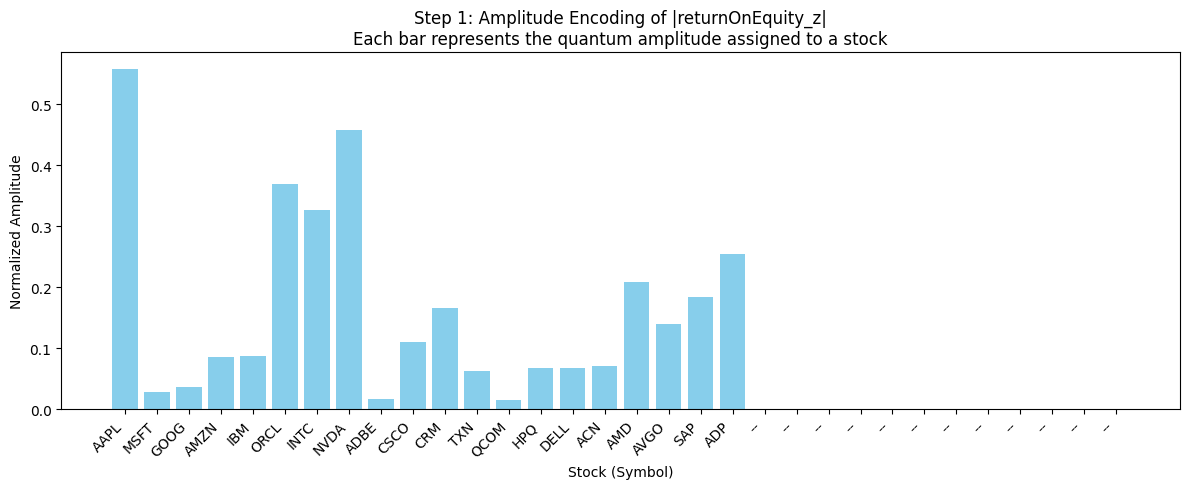

Quantum State Initialization Circuit:
This circuit prepares the amplitude‐encoded state from the classical data.


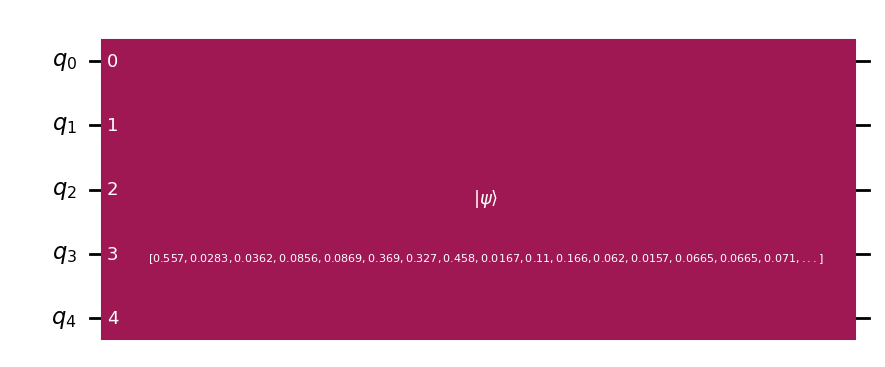

In [29]:
# Compute the z–score for "returnOnEquity" (filling missing values with the median)
stock_data["returnOnEquity_z"] = zscore(stock_data["returnOnEquity"].fillna(stock_data["returnOnEquity"].median()))

# Use the absolute z–score values for amplitude encoding.
z_array = np.abs(stock_data["returnOnEquity_z"].values)

# Create the classical state vector
if len(z_array) < dim:
    state_vector = np.pad(z_array, (0, dim - len(z_array)), mode='constant')
else:
    state_vector = z_array[:dim]

# Normalize the state vector to represent valid quantum amplitudes.
norm = np.linalg.norm(state_vector)
state_vector = state_vector / norm

# Visualization: amplitude–encoded state.
plt.figure(figsize=(12, 5))
plt.bar(range(len(state_vector)), state_vector, color='skyblue')
plt.xticks(range(len(state_vector)), symbols, rotation=45, ha='right')
plt.xlabel("Stock (Symbol)")
plt.ylabel("Normalized Amplitude")
plt.title("Step 1: Amplitude Encoding of |returnOnEquity_z|\nEach bar represents the quantum amplitude assigned to a stock")
plt.tight_layout()
plt.show()
print("Quantum State Initialization Circuit:\nThis circuit prepares the amplitude‐encoded state from the classical data.")
qc_init.draw("mpl")


# **2. ORACLE CONSTRUCTION (USING A THRESHOLD)**

In [30]:
def create_oracle_amplitude(threshold, z_values, dim):
    """
    Build an oracle gate that flips the phase (i.e., multiplies by -1)
    if the unnormalized absolute z–score exceeds the threshold.
    """
    diagonal = [(-1 if val > threshold else 1) for val in z_values]
    if len(diagonal) < dim:
        diagonal.extend([1]*(dim - len(diagonal)))
    return Diagonal(np.array(diagonal)).to_gate(label="OracleGate")

# Set an initial threshold value (in the same units as z_array)
initial_threshold = 1.5
oracle_gate_initial = create_oracle_amplitude(initial_threshold, z_array, dim)

# **3. QUANTUM COUNTING & THRESHOLD ADJUSTMENT**

ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)


Iteration 0: Threshold T = 1.50, Estimated marked states = 16.00


ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)


Iteration 1: Threshold T = 1.75, Estimated marked states = 16.00


ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)


...

ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)


Iteration 3: Threshold T = 2.25, Estimated marked states = 4.69


ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)


Iteration 4: Threshold T = 2.25, Estimated marked states = 4.69
Adjusted threshold: 2.25
Final quantum counting histogram:


<Figure size 800x400 with 0 Axes>

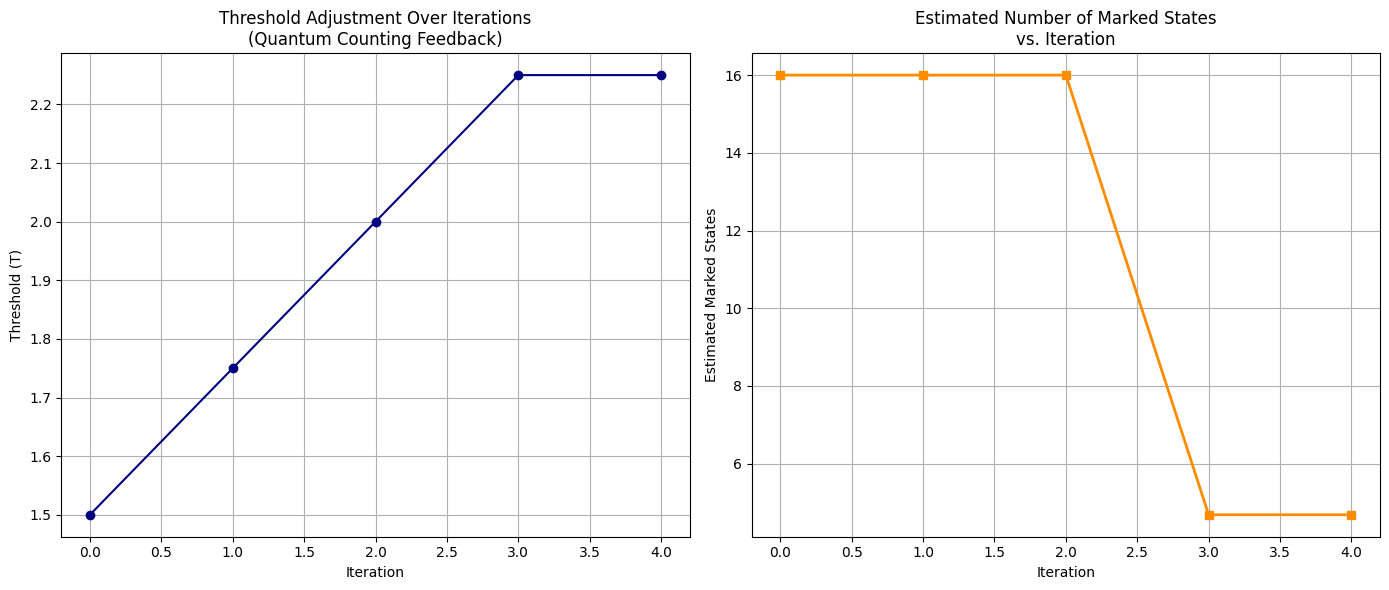

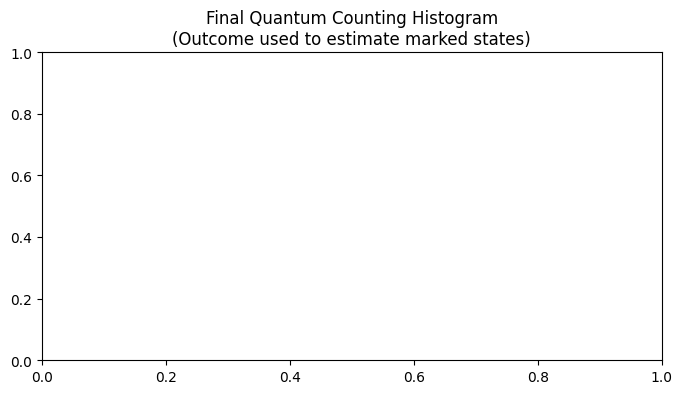

In [42]:
def build_grover_operator(oracle_gate, n_qubits):
    """
    Build the Grover operator (oracle followed by a diffusion operator)
    for the given number of system qubits.
    """
    grover_qc = QuantumCircuit(n_qubits, name="GroverOp")
    grover_qc.append(oracle_gate, list(range(n_qubits)))
    # Diffusion operator:
    grover_qc.h(range(n_qubits))
    grover_qc.x(range(n_qubits))
    grover_qc.h(n_qubits-1)
    grover_qc.mcx(list(range(n_qubits-1)), n_qubits-1, mode='noancilla')
    grover_qc.h(n_qubits-1)
    grover_qc.x(range(n_qubits))
    grover_qc.h(range(n_qubits))
    return grover_qc.to_gate(label="GroverOp")

def quantum_counting_circuit(oracle_gate, n_system_qubits=5, t_count=3):
    """
    Build a quantum counting circuit that uses t_count counting qubits
    and n_system_qubits system qubits to estimate the number of marked states.
    """
    total_qubits = t_count + n_system_qubits
    qc = QuantumCircuit(total_qubits, t_count)
    counting_qubits = list(range(t_count))
    system_qubits = list(range(t_count, t_count + n_system_qubits))

    # 1. Put counting qubits in superposition.
    qc.h(counting_qubits)
    # 2. Put system qubits in superposition.
    qc.h(system_qubits)

    # 3. Build and apply the controlled Grover operator.
    grover_gate = build_grover_operator(oracle_gate, n_system_qubits)
    for i in range(t_count):
        reps = 2 ** i
        for _ in range(reps):
            controlled_g = grover_gate.control(1)
            qc.append(controlled_g, [counting_qubits[i]] + system_qubits)

    # 4. Inverse QFT on counting qubits.
    qc.append(QFT(t_count, do_swaps=True).inverse(), counting_qubits)

    # 5. Measure the counting qubits.
    qc.measure(counting_qubits, list(range(t_count)))
    return qc

def run_simulation(qc, shots=1024):
    simulator = AerSimulator()
    compiled_circuit = transpile(qc, simulator)
    job = simulator.run(compiled_circuit, shots=shots)
    return job.result().get_counts(compiled_circuit)

def interpret_counting_result(counts, t_count=3):
    # Choose the most frequent result from the counting qubits.
    best_outcome, best_count = max(counts.items(), key=lambda x: x[1])
    measured_value = int(best_outcome[::-1], 2)  # Reverse bit order if necessary.
    return best_outcome, measured_value

# Record data.
iterations = []
thresholds = []
estimated_marked = []
counting_histograms = []

max_iters = 5
T = initial_threshold

for i in range(max_iters):
    oracle_gate = create_oracle_amplitude(T, z_array, dim)
    qc_count = quantum_counting_circuit(oracle_gate, n_system_qubits=num_system_qubits, t_count=3)
    counts = run_simulation(qc_count, shots=1024)
    outcome, measured_value = interpret_counting_result(counts, t_count=3)
    # For t_count=3, 2^t_count = 8; approximate the number of marked states:
    N = dim
    M_estimated = N * (np.sin(np.pi * measured_value / 8))**2
    print(f"Iteration {i}: Threshold T = {T:.2f}, Estimated marked states = {M_estimated:.2f}")

    iterations.append(i)
    thresholds.append(T)
    estimated_marked.append(M_estimated)
    counting_histograms.append(counts)
    desired_marked_low = 1
    desired_marked_high = 6
    lower_bound = T - 0.5
    upper_bound = T + 0.5

    # Adjust threshold: if too many states are marked, raise T; too few, lower T.
    if M_estimated < desired_marked_low:
        T = (T + lower_bound) / 2.0  # or use binary search update
    elif M_estimated > desired_marked_high:
        T = (T + upper_bound) / 2.0

T_adjusted = T
print(f"Adjusted threshold: {T_adjusted:.2f}")

# Plot threshold adjustment evolution.
print("Final quantum counting histogram:")
plt.figure(figsize=(8,4))
plot_histogram(counting_histograms[-1])
plt.show()

plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.plot(iterations, thresholds, marker='o', linestyle='-', color='navy')
plt.xlabel("Iteration")
plt.ylabel("Threshold (T)")
plt.title("Threshold Adjustment Over Iterations\n(Quantum Counting Feedback)")
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(iterations, estimated_marked, marker='s', color='darkorange', linestyle='-', linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("Estimated Marked States")
plt.title("Estimated Number of Marked States\nvs. Iteration")
plt.grid(True)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
plot_histogram(counting_histograms[-1])
plt.title("Final Quantum Counting Histogram\n(Outcome used to estimate marked states)")
plt.show()


# **4. GROVER’S ALGORITHM & FINAL VISUALIZATION**

ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.11/dist-packages/qiskit/providers/__init__.py)


Grover's Algorithm Circuit (with Adjusted Oracle):


<ipython-input-44-6cf5a27989a4>:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Symbol", y="Count", data=grover_df, palette="viridis")


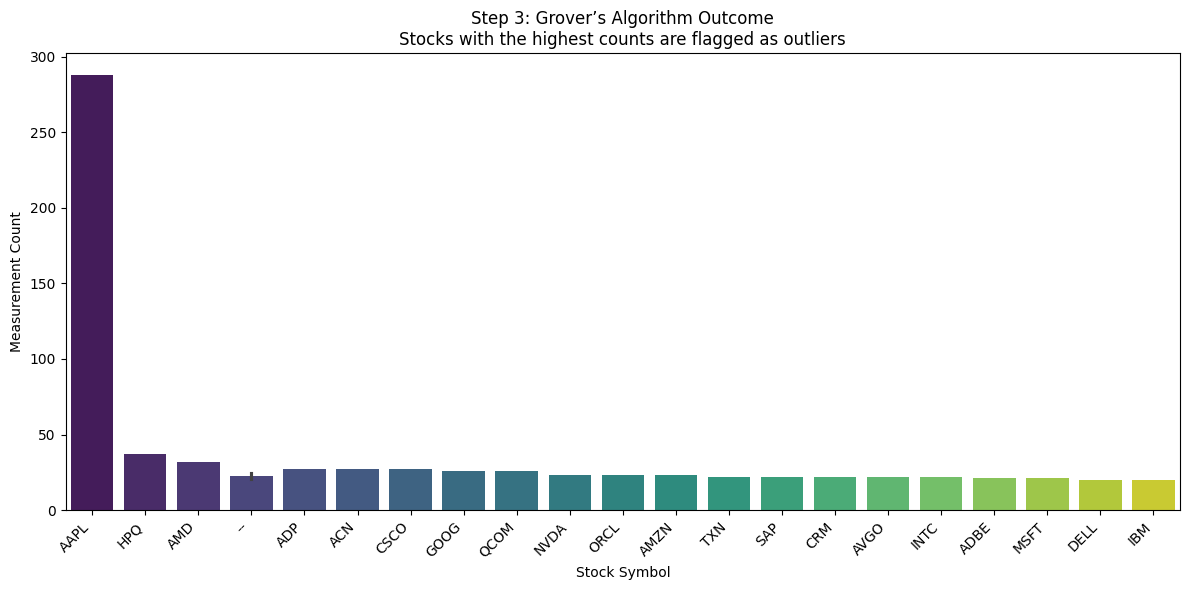

<ipython-input-44-6cf5a27989a4>:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="symbol", y="returnOnEquity_z", data=stock_data, palette="Blues_d")


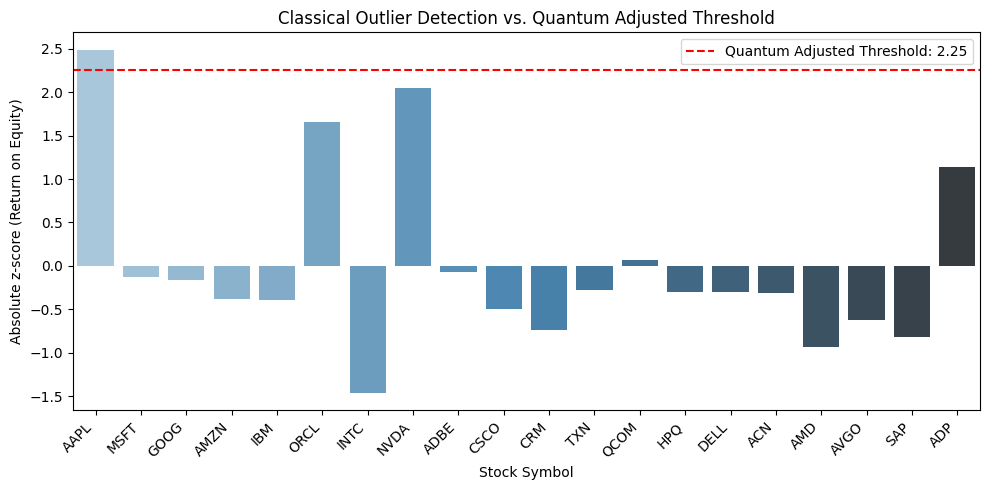

In [44]:
def grover_circuit_amplitude(oracle_gate, n_qubits=5, num_iterations=1):
    """
    Build a Grover circuit that applies the oracle and the diffusion operator.
    """
    qc = QuantumCircuit(n_qubits, n_qubits)
    qc.h(range(n_qubits))  # initialize to uniform superposition
    for _ in range(num_iterations):
        qc.append(oracle_gate, range(n_qubits))
        qc.h(range(n_qubits))
        qc.x(range(n_qubits))
        qc.h(n_qubits-1)
        qc.mcx(list(range(n_qubits-1)), n_qubits-1, mode='noancilla')
        qc.h(n_qubits-1)
        qc.x(range(n_qubits))
        qc.h(range(n_qubits))
    qc.measure(range(n_qubits), range(n_qubits))
    return qc

# Build the final oracle with the adjusted threshold.
oracle_final = create_oracle_amplitude(T_adjusted, z_array, dim)

# Construct and run the Grover circuit.
qc_grover = grover_circuit_amplitude(oracle_final, n_qubits=num_system_qubits, num_iterations=1)
grover_counts = run_simulation(qc_grover, shots=1024)

# Create a DataFrame mapping measurement results (binary string -> index) and then to stock symbol.
grover_df = pd.DataFrame(list(grover_counts.items()), columns=['State', 'Count'])
grover_df['Index'] = grover_df['State'].apply(lambda s: int(s, 2))
grover_df['Symbol'] = grover_df['Index'].apply(lambda i: symbols[i] if i < len(symbols) else "N/A")
grover_df.sort_values("Count", ascending=False, inplace=True)

print("Grover's Algorithm Circuit (with Adjusted Oracle):")
qc_grover.draw("mpl")


# Convert measurement results to a DataFrame:
grover_df = pd.DataFrame(list(grover_counts.items()), columns=['State', 'Count'])
grover_df['Index'] = grover_df['State'].apply(lambda s: int(s, 2))
grover_df['Symbol'] = grover_df['Index'].apply(lambda i: symbols[i] if i < len(symbols) else "N/A")
grover_df.sort_values("Count", ascending=False, inplace=True)

plt.figure(figsize=(12,6))
sns.barplot(x="Symbol", y="Count", data=grover_df, palette="viridis")
plt.xlabel("Stock Symbol")
plt.ylabel("Measurement Count")
plt.title("Step 3: Grover’s Algorithm Outcome\nStocks with the highest counts are flagged as outliers")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Classical outlier extraction for comparison:
classical_outliers = stock_data[stock_data["returnOnEquity_z"].abs() > T_adjusted]
plt.figure(figsize=(10,5))
sns.barplot(x="symbol", y="returnOnEquity_z", data=stock_data, palette="Blues_d")
plt.axhline(y=T_adjusted, color='red', linestyle='--', label=f"Quantum Adjusted Threshold: {T_adjusted:.2f}")
plt.xlabel("Stock Symbol")
plt.ylabel("Absolute z-score (Return on Equity)")
plt.title("Classical Outlier Detection vs. Quantum Adjusted Threshold")
plt.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
